# NB01: Constant bias model calibration — soda / pop / coke

Companion notebook (EPL series) exploring the **constant (scalar) bias model** introduced in
Section 4 of "Statistical physics of language change inferred from time evolving maps"
(Burridge & Vaux).

**Goal:** calibrate the constant bias model to the soda/pop/coke MAP field over the training
window [1980, 1985], then evolve it forward to 1995 and compare the forecast against the
empirical MAP field.

**Prerequisites:** this notebook uses
- Pre-computed MAP fields from Section 2 (`data/probability_fields/`)
- Migration generator $W$ and copying generator $L$ (`spatial_model.py`)


In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path().resolve().parent / 'src'))

import glob

import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy.spatial import distance_matrix
from scipy.optimize import minimize

import spatial_model as sm


In [2]:
repo_root   = Path().resolve().parents[1]
voronoi_dir = repo_root / 'data' / 'voronois'
p_field_dir = repo_root / 'data' / 'probability_fields'

cmap       = 'RdYlBu_r'
n_demes    = 4000
start_year = 1950
end_year   = 2000
J          = 0.1    # copying rate (fixed, see Section 3)


In [3]:
gdf_voronoi = gpd.read_file(voronoi_dir / f'Voronoi_{n_demes}_raw_kmeans_demes.gpkg')
DX   = np.column_stack([gdf_voronoi.x.values, gdf_voronoi.y.values])
dmat = distance_matrix(DX, DX) / 1e3
pops = gdf_voronoi['pop'].values
N    = len(pops)
print(f'N = {N} cells')


N = 4000 cells


In [4]:
# Build migration generator W and copying generator L
# (same parameters as Section 3/4 — may take ~2 min each)
d0, gamma0, gamma1, alpha_mig, lambda_bar = 48.91, 5.57, -0.35, 0.60, 0.063
R = 100   # copying range (km)

c = sm.get_c(pops, dmat, d0, gamma0, gamma1, alpha_mig, lambda_bar)

print('Building W ...')
W = sm.migration_generator(dmat, pops, d0, gamma0, gamma1, alpha_mig, c)
print('Building L ...')
L = sm.diffusion_generator(dmat, pops, R)
print('Done.')


Building W ...
Building L ...
Done.


In [5]:
soda_files = glob.glob(str(p_field_dir / 'v_4_soda_pop_coke_*.npy'))
assert soda_files, 'No soda_pop_coke v_4 field found in data/probability_fields/'
P = np.load(soda_files[0])   # (N, T, K)
K = P.shape[2]
variant_names = ['soda', 'pop', 'coke']
print(f'P shape: {P.shape}')


P shape: (4000, 51, 3)


## Calibrate the constant bias model on [1980, 1985]

The constant bias model fits a single accommodation factor $\beta$ and a spatially uniform
bias vector $\mathbf{s}$ (one value per variant) by minimising the mean-squared residual
between empirical MAP field increments and the model's predicted increments (see Section 4,
eq. 4.1).

In [6]:
t_train0 = 1980 - start_year
t_train1 = 1985 - start_year

obj = sm.make_objective(P, W, L, t_train0, t_train1, J)
res = minimize(obj, np.zeros(K + 1))   # default BFGS

beta_fit = res.x[0]
s_fit    = res.x[1:]
print(f'Calibration window: 1980–1985')
print(f'β = {beta_fit:.3f}')
print(f's = {s_fit.round(4)}  ({", ".join(variant_names)})')


Calibration window: 1980–1985
β = 0.210
s = [-0.0194  0.0251 -0.0056]  (soda, pop, coke)


## Forward prediction to 1995

Using the fitted $(\beta, \mathbf{s})$, the model is initialised from the empirical MAP field
at 1985 and integrated forward 10 years to 1995.

In [7]:
T_fwd   = 1995 - 1985
X0      = P[:, t_train1, :].copy()
s_field = np.tile(s_fit, (N, 1))   # spatially uniform bias, broadcast to all demes

mod   = sm.model(W, L, J, s_field, beta_fit, X0)
xsol  = mod.solve(np.arange(T_fwd + 1))   # (T_fwd+1, N, K)
print(f'xsol shape: {xsol.shape}')


xsol shape: (11, 4000, 3)


## Figure: model vs. data, 1985 and 1995

Top row: constant bias model prediction (soda fraction). Bottom row: empirical MAP field
(soda fraction).

In [ ]:
variant_idx = 0   # soda
plot_years  = [1985, 1995]
labels      = [['(a)', '(b)'], ['(c)', '(d)']]

# panel aspect ratio (w/h) matches the Voronoi tessellation's bounding box (~1.56)
fig, axs = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
fig.set_constrained_layout_pads(w_pad=0.02, h_pad=0.02, wspace=0.01, hspace=0.02)

for col, yr in enumerate(plot_years):
    t_mod = yr - 1985
    t_emp = yr - start_year

    ax_mod = axs[0, col]
    gdf_voronoi.plot(column=xsol[t_mod, :, variant_idx], ax=ax_mod,
                      cmap=cmap, vmin=0, vmax=1, linewidth=0.05, edgecolor='k')
    ax_mod.set_axis_off()
    ax_mod.set_title(f'{labels[0][col]} Model — {yr}', fontsize=18)

    ax_emp = axs[1, col]
    gdf_voronoi.plot(column=P[:, t_emp, variant_idx], ax=ax_emp,
                      cmap=cmap, vmin=0, vmax=1, linewidth=0.05, edgecolor='k')
    ax_emp.set_axis_off()
    ax_emp.set_title(f'{labels[1][col]} Data — {yr}', fontsize=18)

sm_cbar = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
cbar = fig.colorbar(sm_cbar, ax=axs, shrink=0.7, pad=0.02, label=f'{variant_names[variant_idx]} fraction')
cbar.set_label(f'{variant_names[variant_idx]} fraction', fontsize=16)
cbar.ax.tick_params(labelsize=14)

fig_dir = repo_root / 'figures'
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / 'nb01_constant_bias_soda_1985_1995.png', dpi=300, bbox_inches='tight')

plt.show()


## Section 2: Calibration on [1975, 1980], forecast to 1995

Same constant bias model, calibrated on the earlier 5-year window [1975, 1980] and evolved
forward 15 years to 1995 — a longer forecast horizon than the [1980, 1985] calibration above.

In [14]:
t_train0_75 = 1975 - start_year
t_train1_75 = 1980 - start_year

obj_75 = sm.make_objective(P, W, L, t_train0_75, t_train1_75, J)
res_75 = minimize(obj_75, np.zeros(K + 1))   # default BFGS

beta_fit_75 = res_75.x[0]
s_fit_75    = res_75.x[1:]
print(f'Calibration window: 1975–1980')
print(f'β = {beta_fit_75:.3f}')
print(f's = {s_fit_75.round(4)}  ({", ".join(variant_names)})')


Calibration window: 1975–1980
β = 0.209
s = [-0.0181  0.0218 -0.0037]  (soda, pop, coke)


In [15]:
T_fwd_75   = 1995 - 1980
X0_75      = P[:, t_train1_75, :].copy()
s_field_75 = np.tile(s_fit_75, (N, 1))   # spatially uniform bias, broadcast to all demes

mod_75  = sm.model(W, L, J, s_field_75, beta_fit_75, X0_75)
xsol_75 = mod_75.solve(np.arange(T_fwd_75 + 1))   # (T_fwd_75+1, N, K)
print(f'xsol_75 shape: {xsol_75.shape}')


xsol_75 shape: (16, 4000, 3)


### Figure: model vs. data, 1980 and 1995

Top row: constant bias model prediction (soda fraction), calibrated on [1975, 1980]. Bottom
row: empirical MAP field (soda fraction).

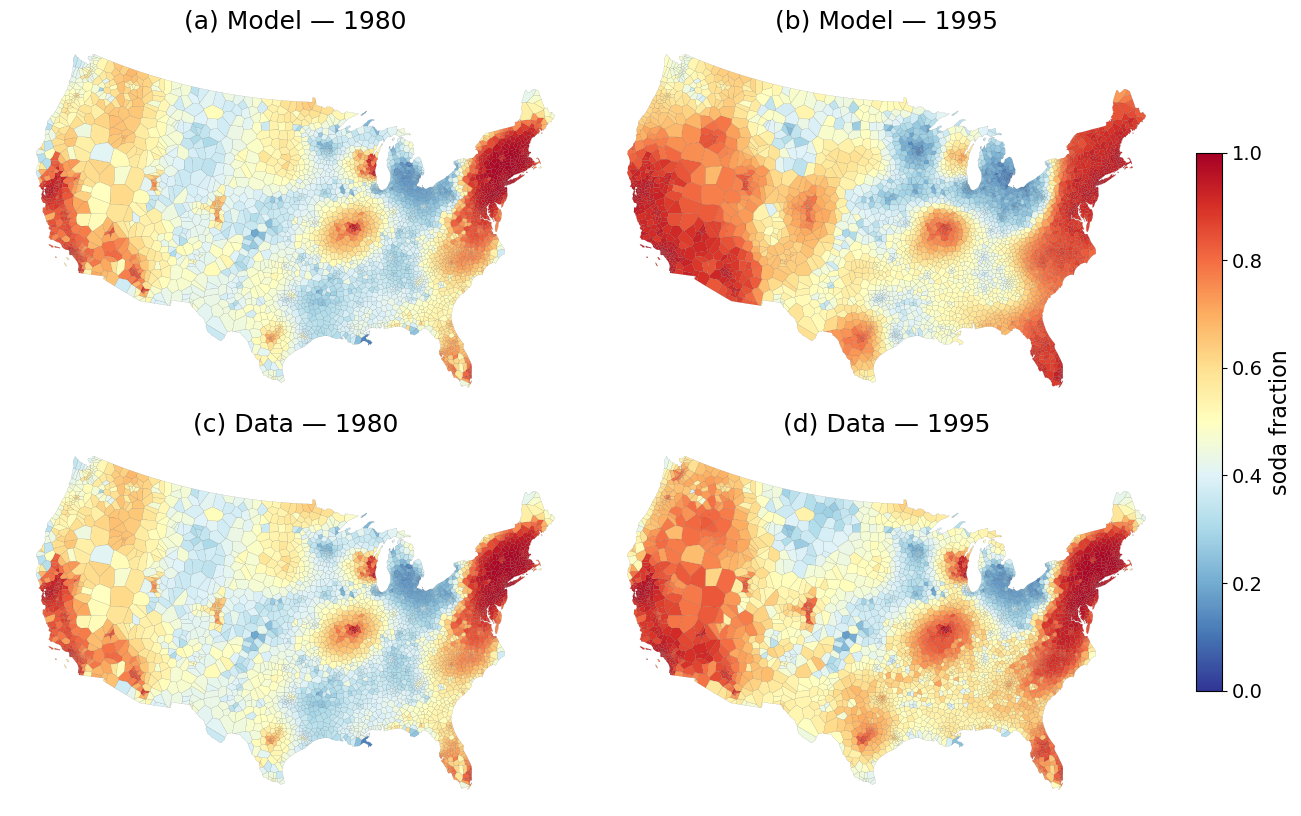

In [16]:
variant_idx  = 0   # soda
plot_years_75 = [1980, 1995]
labels        = [['(a)', '(b)'], ['(c)', '(d)']]

# panel aspect ratio (w/h) matches the Voronoi tessellation's bounding box (~1.56)
fig, axs = plt.subplots(2, 2, figsize=(13, 8), constrained_layout=True)
fig.set_constrained_layout_pads(w_pad=0.02, h_pad=0.02, wspace=0.01, hspace=0.02)

for col, yr in enumerate(plot_years_75):
    t_mod = yr - 1980
    t_emp = yr - start_year

    ax_mod = axs[0, col]
    gdf_voronoi.plot(column=xsol_75[t_mod, :, variant_idx], ax=ax_mod,
                      cmap=cmap, vmin=0, vmax=1, linewidth=0.05, edgecolor='k')
    ax_mod.set_axis_off()
    ax_mod.set_title(f'{labels[0][col]} Model — {yr}', fontsize=18)

    ax_emp = axs[1, col]
    gdf_voronoi.plot(column=P[:, t_emp, variant_idx], ax=ax_emp,
                      cmap=cmap, vmin=0, vmax=1, linewidth=0.05, edgecolor='k')
    ax_emp.set_axis_off()
    ax_emp.set_title(f'{labels[1][col]} Data — {yr}', fontsize=18)

sm_cbar = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(0, 1))
cbar = fig.colorbar(sm_cbar, ax=axs, shrink=0.7, pad=0.02, label=f'{variant_names[variant_idx]} fraction')
cbar.set_label(f'{variant_names[variant_idx]} fraction', fontsize=16)
cbar.ax.tick_params(labelsize=14)

fig_dir = repo_root / 'figures'
fig_dir.mkdir(exist_ok=True)
fig.savefig(fig_dir / 'nb01_constant_bias_soda_1980_1995.png', dpi=300, bbox_inches='tight')

plt.show()
